# Diabetes Prediction System using a Leakage-Safe Artificial Neural Network

**Course:** 21CSE326T – Artificial Neural Networks  
**Programme:** B.Tech. CSE (Artificial Intelligence and Machine Learning)  
**Institution:** SRM Institute of Science and Technology, Tiruchirappalli  

| Student | Register number |
|---------|-----------------|
| Shanmugapriyan J | RA2411026050011 |
| Deepak V F | RA2411026050015 |

III Year / V Semester, Section A

This notebook is the **entire project code** for classroom submission. It loads the local Pima Indians Diabetes table, recodes medically impossible zeros, trains an 8–16–8–1 feed-forward ANN inside a leakage-safe pipeline, and compares it with a dummy classifier, logistic regression, and a random forest.

**Educational model only — not a diagnostic tool.** The 768 rows are adult Pima women (age ≥ 21). Do not use these outputs for clinical decisions.


## 1. Setup

Install `pandas`, `numpy`, `scikit-learn`, `imbalanced-learn`, `matplotlib`, and `seaborn` if they are missing. The notebook looks for the CSV next to this file, in `data/`, or (on Colab) after you upload it.


In [1]:
import os
import random
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

RANDOM_SEED = 42
N_SPLITS = 5
os.environ["PYTHONHASHSEED"] = str(RANDOM_SEED)
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["figure.dpi"] = 110
print("Libraries loaded. Seed =", RANDOM_SEED)

Libraries loaded. Seed = 42


## 2. Constants and medical zero policy

Zeros are recoded as missing only for Glucose, BloodPressure, SkinThickness, Insulin, and BMI. **Pregnancies = 0 is valid** (never pregnant) and is kept.


In [2]:
FEATURE_COLUMNS = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
]
TARGET_COLUMN = "Outcome"
ALL_COLUMNS = FEATURE_COLUMNS + [TARGET_COLUMN]
ZERO_AS_MISSING_COLUMNS = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
]
DISCLAIMER = (
    "Educational model only — not a medical diagnostic tool. "
    "The Pima Indians Diabetes dataset is small (768 rows) and limited to "
    "adult women (age 21+) of Pima heritage."
)
print(DISCLAIMER)
print("Zero-as-missing columns:", ZERO_AS_MISSING_COLUMNS)
print("Valid zero kept: Pregnancies")

Educational model only — not a medical diagnostic tool. The Pima Indians Diabetes dataset is small (768 rows) and limited to adult women (age 21+) of Pima heritage.
Zero-as-missing columns: ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
Valid zero kept: Pregnancies


## 3. Load the local dataset

The code never downloads the file. Place `pima_indians_diabetes.csv` in `data/` or upload it if you are on Colab.


In [3]:
def find_dataset() -> Path:
    here = Path.cwd().resolve()
    candidates = [
        here / "data" / "pima_indians_diabetes.csv",
        here.parent / "data" / "pima_indians_diabetes.csv",
        here / "pima_indians_diabetes.csv",
        Path("/content") / "pima_indians_diabetes.csv",
    ]
    # When the notebook lives in notebooks/, the project data folder is one level up.
    if here.name == "notebooks":
        candidates.insert(0, here.parent / "data" / "pima_indians_diabetes.csv")
    for path in candidates:
        if path.exists():
            return path
    raise FileNotFoundError(
        "Pima CSV not found. Put pima_indians_diabetes.csv in data/ "
        "or upload it to the working directory. The notebook does not download data."
    )


data_path = find_dataset()
df = pd.read_csv(data_path)
df.columns = [c.strip() for c in df.columns]
print("Loaded:", data_path)
print("Shape:", df.shape)
df.head()

Loaded: /Users/deepakvf/ANN/diabetes_ann/data/pima_indians_diabetes.csv
Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 4. Dataset profile


In [4]:
print(df.info())
print()
print(df[TARGET_COLUMN].value_counts().rename("count"))
print()
print("Class share:")
print(df[TARGET_COLUMN].value_counts(normalize=True).round(3))
print()
print("Duplicate rows:", int(df.duplicated().sum()))
print("Empty cells:", int(df.isna().sum().sum()))
print()
zeros = (df[FEATURE_COLUMNS] == 0).sum()
print("Zero counts (raw file):")
print(zeros)
print()
print(df[FEATURE_COLUMNS + [TARGET_COLUMN]].describe().T.round(2))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
None

Outcome
0    500
1    268
Name: count, dtype: int64

Class share:
Outcome
0    0.651
1    0.349
Name: proportion, dtype: float64

Duplicate rows: 0
Empty cells: 0

Zero counts (raw file):
Pregnancies                 111
Glucose       

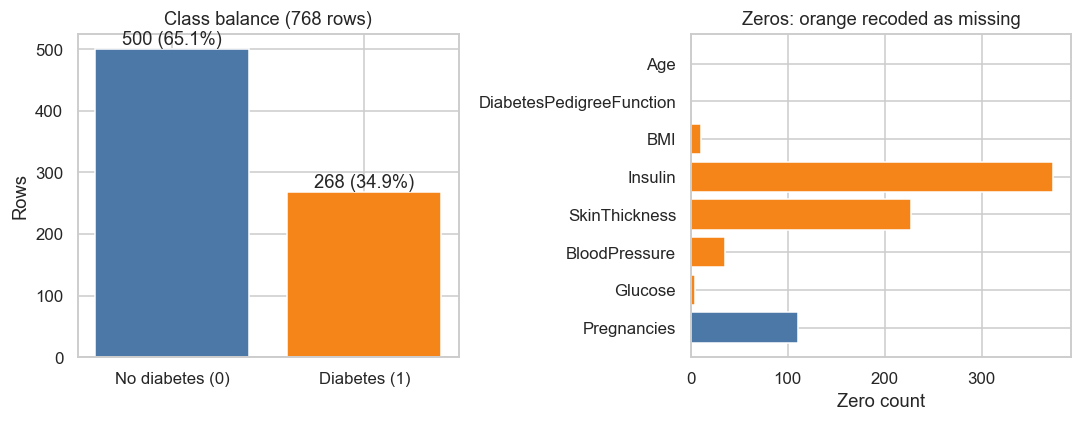

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
counts = df[TARGET_COLUMN].value_counts().sort_index()
axes[0].bar(["No diabetes (0)", "Diabetes (1)"], counts.values, color=["#4C78A8", "#F58518"])
axes[0].set_ylabel("Rows")
axes[0].set_title("Class balance (768 rows)")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 8, f"{v} ({v / len(df):.1%})", ha="center")

colors = ["#F58518" if c in ZERO_AS_MISSING_COLUMNS else "#4C78A8" for c in FEATURE_COLUMNS]
axes[1].barh(FEATURE_COLUMNS, zeros.values, color=colors)
axes[1].set_xlabel("Zero count")
axes[1].set_title("Zeros: orange recoded as missing")
plt.tight_layout()
plt.show()

## 5. Exploratory plots

After recoding impossible zeros, glucose, BMI, age and pregnancies separate the two classes most clearly.


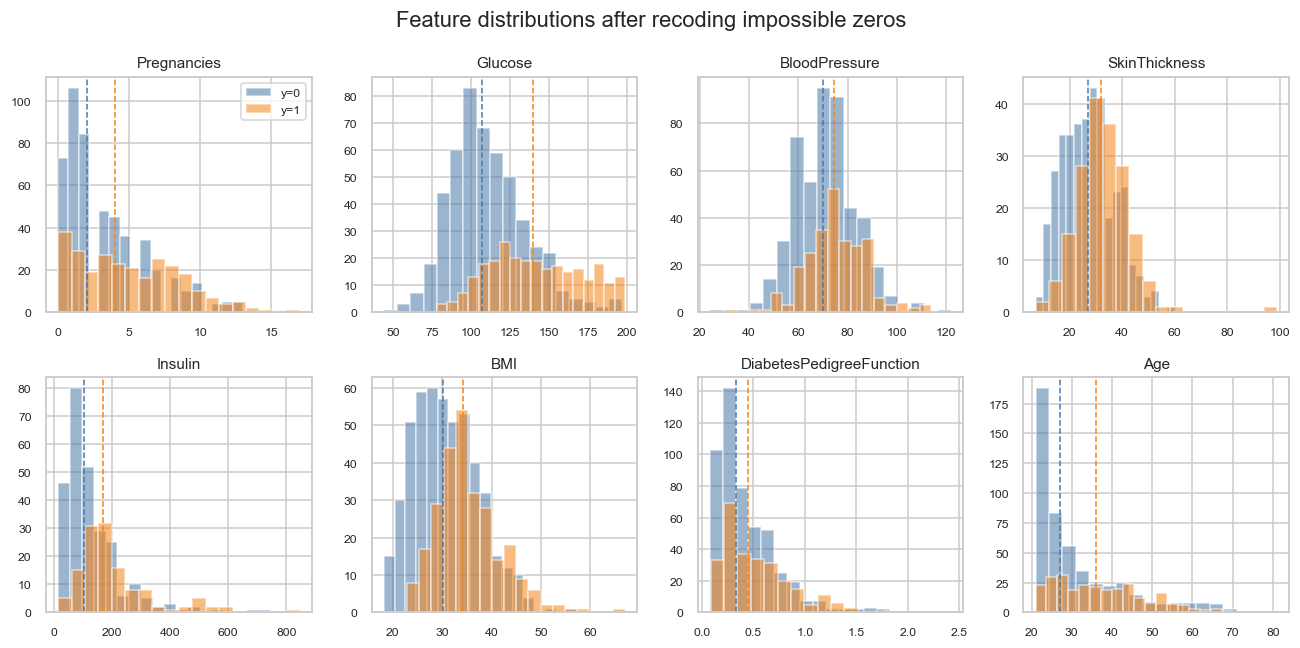

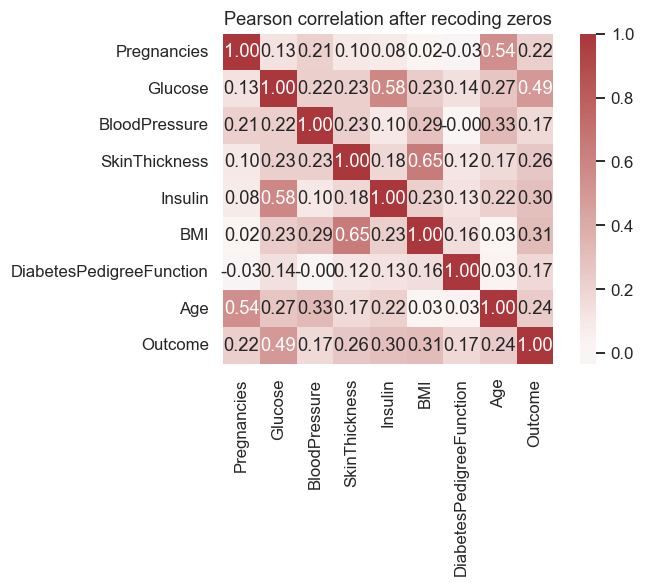

Correlation with Outcome:
Glucose                     0.495
BMI                         0.314
Insulin                     0.303
SkinThickness               0.259
Age                         0.238
Pregnancies                 0.222
DiabetesPedigreeFunction    0.174
BloodPressure               0.171
Name: Outcome, dtype: float64


In [6]:
recoded = df.copy()
for col in ZERO_AS_MISSING_COLUMNS:
    recoded[col] = recoded[col].mask(recoded[col] == 0)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, col in zip(axes.ravel(), FEATURE_COLUMNS):
    for label, color in [(0, "#4C78A8"), (1, "#F58518")]:
        vals = recoded.loc[recoded[TARGET_COLUMN] == label, col].dropna()
        ax.hist(vals, bins=18, alpha=0.55, color=color, label=f"y={label}")
        ax.axvline(vals.median(), color=color, linestyle="--", linewidth=1)
    ax.set_title(col, fontsize=10)
    ax.tick_params(labelsize=8)
axes[0, 0].legend(fontsize=8)
plt.suptitle("Feature distributions after recoding impossible zeros")
plt.tight_layout()
plt.show()

corr = recoded[FEATURE_COLUMNS + [TARGET_COLUMN]].corr()
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True)
plt.title("Pearson correlation after recoding zeros")
plt.tight_layout()
plt.show()
print("Correlation with Outcome:")
print(corr[TARGET_COLUMN].drop(TARGET_COLUMN).sort_values(ascending=False).round(3))

## 6. Leakage-safe preprocessing

Every learned step (imputer, scaler, optional selector, oversampler, network weights) is fitted on the **training fold only**. The test fold is transformed with those fitted objects and never resampled.


In [7]:
class ZeroAsMissing(BaseEstimator, TransformerMixin):
    """Replace 0 with NaN only where 0 is not a valid adult measurement."""

    def __init__(self, columns=None):
        self.columns = columns

    def fit(self, X, y=None):
        frame = X if isinstance(X, pd.DataFrame) else pd.DataFrame(X)
        self.feature_names_in_ = np.asarray(frame.columns, dtype=object)
        self.columns_ = list(self.columns) if self.columns is not None else list(ZERO_AS_MISSING_COLUMNS)
        return self

    def transform(self, X):
        frame = (X if isinstance(X, pd.DataFrame) else pd.DataFrame(X, columns=self.feature_names_in_)).copy()
        for column in self.columns_:
            if column in frame.columns:
                numeric = pd.to_numeric(frame[column], errors="coerce")
                frame[column] = numeric.mask(numeric == 0)
        return frame


def build_pipeline(estimator, feature_selection=False, k=5, resample=False, random_state=RANDOM_SEED):
    steps = [
        ("zero_as_missing", ZeroAsMissing(columns=ZERO_AS_MISSING_COLUMNS)),
        ("impute", SimpleImputer(strategy="median")),
        ("select", SelectKBest(score_func=f_classif, k=k) if feature_selection else "passthrough"),
        ("scale", StandardScaler()),
    ]
    if resample:
        steps.append(("resample", RandomOverSampler(sampling_strategy="auto", random_state=random_state)))
    steps.append(("clf", clone(estimator)))
    return ImbPipeline(steps)


print("Pipeline order: zero recode → median impute → optional SelectKBest → scale → optional ROS → classifier")

Pipeline order: zero recode → median impute → optional SelectKBest → scale → optional ROS → classifier


## 7. Models

The ANN is a fully connected 8–16–8–1 multilayer perceptron (289 trainable parameters). Hidden units use ReLU; the output is a sigmoid probability. Training uses Adam, L2 (`alpha = 0.001`), batch size 32, and early stopping on a 15% validation split taken from the training fold.


In [8]:
def make_estimators(random_state=RANDOM_SEED):
    return {
        "Dummy (majority)": DummyClassifier(strategy="most_frequent", random_state=random_state),
        "Logistic regression": LogisticRegression(
            max_iter=2000, class_weight="balanced", solver="liblinear", random_state=random_state
        ),
        "Random forest": RandomForestClassifier(
            n_estimators=100, max_depth=6, min_samples_leaf=5,
            class_weight="balanced", n_jobs=1, random_state=random_state,
        ),
        "MLP ANN 8-16-8-1": MLPClassifier(
            hidden_layer_sizes=(16, 8),
            activation="relu",
            solver="adam",
            alpha=1e-3,
            batch_size=32,
            learning_rate_init=0.001,
            max_iter=500,
            early_stopping=True,
            validation_fraction=0.15,
            n_iter_no_change=20,
            random_state=random_state,
        ),
    }


n_params = (8 * 16 + 16) + (16 * 8 + 8) + (8 * 1 + 1)
print("ANN trainable parameters:", n_params)
for name, est in make_estimators().items():
    print(f"  {name}: {est.__class__.__name__}")

ANN trainable parameters: 289
  Dummy (majority): DummyClassifier
  Logistic regression: LogisticRegression
  Random forest: RandomForestClassifier
  MLP ANN 8-16-8-1: MLPClassifier


## 8. Metrics and stratified cross-validation


In [9]:
METRIC_ORDER = ["accuracy", "precision", "recall_sensitivity", "specificity", "f1", "roc_auc", "pr_auc"]


def classification_metrics(y_true, y_pred, y_proba=None):
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    out = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "recall_sensitivity": float(recall_score(y_true, y_pred, zero_division=0)),
        "specificity": float(tn / (tn + fp)) if (tn + fp) else 0.0,
        "f1": float(f1_score(y_true, y_pred, zero_division=0)),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    if y_proba is not None and len(np.unique(y_true)) >= 2:
        out["roc_auc"] = float(roc_auc_score(y_true, y_proba))
        out["pr_auc"] = float(average_precision_score(y_true, y_proba))
    else:
        out["roc_auc"] = 0.5
        out["pr_auc"] = float(np.mean(y_true))
    return out


def predict_proba_positive(estimator, X):
    if hasattr(estimator, "predict_proba"):
        proba = estimator.predict_proba(X)
        return proba[:, 1] if proba.ndim == 2 else proba.ravel()
    return np.asarray(estimator.predict(X), dtype=float)


def cross_validate_model(pipeline, X, y, n_splits=N_SPLITS, random_state=RANDOM_SEED):
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    y_array = np.asarray(y).astype(int)
    oof_pred = np.zeros(len(y_array), dtype=int)
    oof_proba = np.zeros(len(y_array), dtype=float)
    fold_rows = []
    for fold, (tr, te) in enumerate(cv.split(X, y_array), start=1):
        model = clone(pipeline)
        model.fit(X.iloc[tr], y_array[tr])
        pred = np.asarray(model.predict(X.iloc[te])).astype(int)
        proba = predict_proba_positive(model, X.iloc[te])
        oof_pred[te] = pred
        oof_proba[te] = proba
        metrics = classification_metrics(y_array[te], pred, proba)
        metrics["fold"] = fold
        fold_rows.append(metrics)
    fold_frame = pd.DataFrame(fold_rows)
    summary = {
        m: {"mean": float(fold_frame[m].mean()), "std": float(fold_frame[m].std(ddof=1))}
        for m in METRIC_ORDER
    }
    return {
        "summary": summary,
        "fold_metrics": fold_rows,
        "oof_pred": oof_pred,
        "oof_proba": oof_proba,
        "y_true": y_array,
        "confusion_matrix_oof": confusion_matrix(y_array, oof_pred, labels=[0, 1]),
    }


X = df[FEATURE_COLUMNS].copy()
y = df[TARGET_COLUMN].astype(int).copy()
print("X:", X.shape, "  y positives:", int(y.sum()), f"({y.mean():.1%})")

X: (768, 8)   y positives: 268 (34.9%)


## 9. Cross-validated comparison

Same stratified 5-fold splits (seed 42) for every model. The proposed system is the MLP with all 8 features and **training-fold** random oversampling.


In [10]:
configs = [
    ("Dummy (majority)", "Dummy (majority)", False),
    ("Logistic regression", "Logistic regression", True),
    ("Random forest", "Random forest", True),
    ("MLP ANN (no ROS)", "MLP ANN 8-16-8-1", False),
    ("Proposed MLP + ROS", "MLP ANN 8-16-8-1", True),
]
estimators = make_estimators()
results = {}
print("Running stratified 5-fold CV (this may take a minute)...")
for label, est_name, use_ros in configs:
    pipe = build_pipeline(estimators[est_name], resample=use_ros)
    results[label] = cross_validate_model(pipe, X, y)
    s = results[label]["summary"]
    print(
        f"{label:22s}  Acc {s['accuracy']['mean']:.3f}  "
        f"Sens {s['recall_sensitivity']['mean']:.3f}  "
        f"Spec {s['specificity']['mean']:.3f}  "
        f"F1 {s['f1']['mean']:.3f}  "
        f"ROC-AUC {s['roc_auc']['mean']:.3f}  "
        f"PR-AUC {s['pr_auc']['mean']:.3f}"
    )

rows = []
for label, result in results.items():
    row = {"Model": label}
    for m in METRIC_ORDER:
        row[m] = f"{result['summary'][m]['mean']:.3f} ± {result['summary'][m]['std']:.3f}"
    rows.append(row)
cv_table = pd.DataFrame(rows)
cv_table

Running stratified 5-fold CV (this may take a minute)...
Dummy (majority)        Acc 0.651  Sens 0.000  Spec 1.000  F1 0.000  ROC-AUC 0.500  PR-AUC 0.349
Logistic regression     Acc 0.742  Sens 0.709  Spec 0.760  F1 0.659  ROC-AUC 0.834  PR-AUC 0.719


/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_a

Random forest           Acc 0.759  Sens 0.769  Spec 0.754  F1 0.691  ROC-AUC 0.832  PR-AUC 0.702


/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_a

/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_a

MLP ANN (no ROS)        Acc 0.762  Sens 0.571  Spec 0.864  F1 0.625  ROC-AUC 0.832  PR-AUC 0.699


/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_a

/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_a

Proposed MLP + ROS      Acc 0.746  Sens 0.769  Spec 0.734  F1 0.680  ROC-AUC 0.834  PR-AUC 0.696


/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_a

,Model,accuracy,precision,recall_sensitivity,specificity,f1,roc_auc,pr_auc
0,Dummy (majority),0.651 ± 0.002,0.000 ± 0.000,0.000 ± 0.000,1.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.349 ± 0.002
1,Logistic regression,0.742 ± 0.053,0.619 ± 0.077,0.709 ± 0.043,0.760 ± 0.076,0.659 ± 0.053,0.834 ± 0.023,0.719 ± 0.041
2,Random forest,0.759 ± 0.042,0.631 ± 0.057,0.769 ± 0.038,0.754 ± 0.066,0.691 ± 0.038,0.832 ± 0.022,0.702 ± 0.013
3,MLP ANN (no ROS),0.762 ± 0.033,0.698 ± 0.078,0.571 ± 0.058,0.864 ± 0.047,0.625 ± 0.048,0.832 ± 0.033,0.699 ± 0.063
4,Proposed MLP + ROS,0.746 ± 0.046,0.613 ± 0.067,0.769 ± 0.021,0.734 ± 0.069,0.680 ± 0.044,0.834 ± 0.024,0.696 ± 0.056


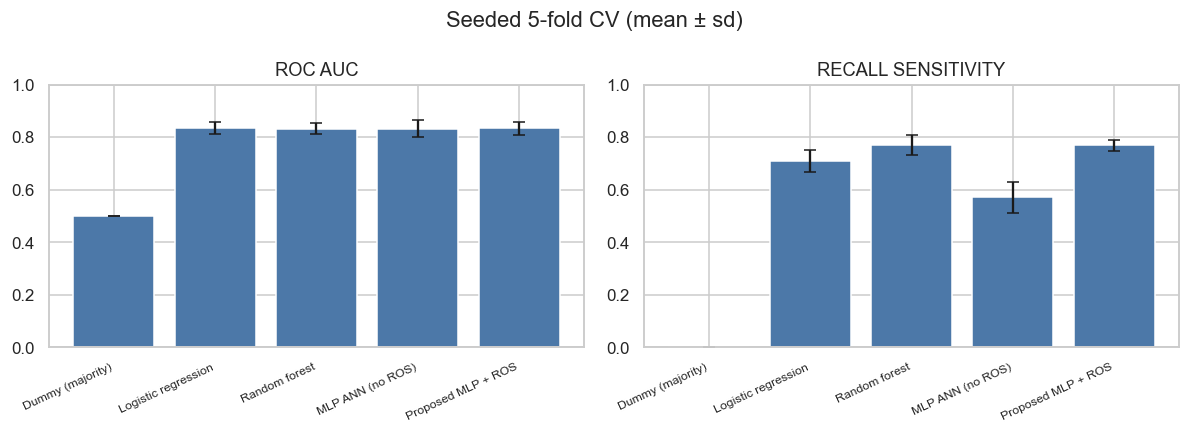

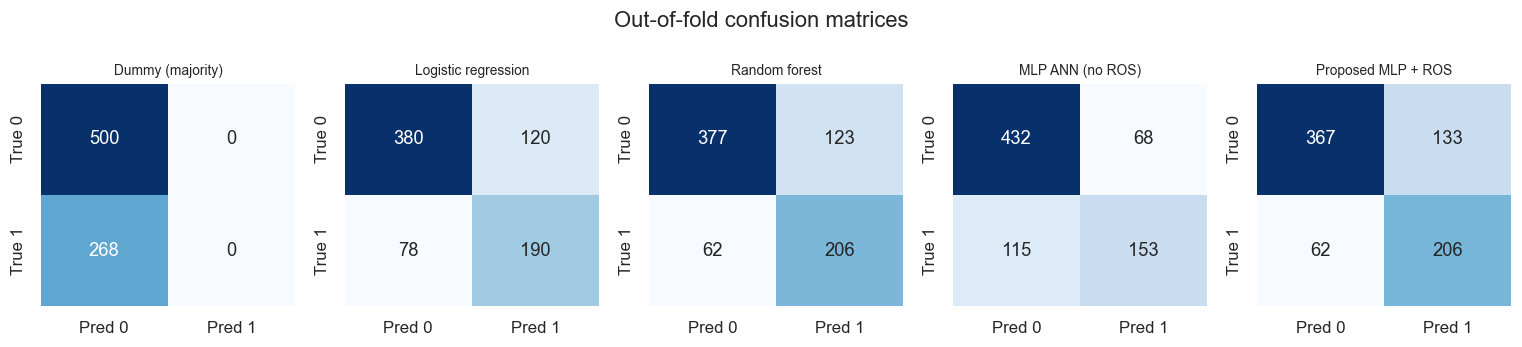

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
labels = list(results)
for metric, ax in zip(["roc_auc", "recall_sensitivity"], axes):
    means = [results[n]["summary"][metric]["mean"] for n in labels]
    stds = [results[n]["summary"][metric]["std"] for n in labels]
    ax.bar(range(len(labels)), means, yerr=stds, capsize=4, color="#4C78A8")
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=25, ha="right", fontsize=8)
    ax.set_ylim(0, 1)
    ax.set_title(metric.replace("_", " ").upper())
plt.suptitle("Seeded 5-fold CV (mean ± sd)")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(results), figsize=(14, 3.2))
for ax, (name, result) in zip(axes, results.items()):
    cm = result["confusion_matrix_oof"]
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Pred 0", "Pred 1"], yticklabels=["True 0", "True 1"])
    ax.set_title(name, fontsize=9)
plt.suptitle("Out-of-fold confusion matrices")
plt.tight_layout()
plt.show()

## 10. Hold-out test (80/20)

Design choices stay fixed. The 154-row hold-out set is scored once.


In [12]:
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_SEED
)
print(f"Train {len(X_tr)}  Test {len(X_te)}  Test positives {int(y_te.sum())}")

holdout = {}
estimators = make_estimators()
for label, est_name, use_ros in configs:
    if label.startswith("Dummy"):
        continue
    pipe = build_pipeline(estimators[est_name], resample=use_ros)
    pipe.fit(X_tr, y_tr)
    pred = pipe.predict(X_te)
    proba = predict_proba_positive(pipe, X_te)
    holdout[label] = {
        "metrics": classification_metrics(y_te, pred, proba),
        "pred": pred,
        "proba": proba,
        "pipe": pipe,
    }

ho_rows = []
for label, item in holdout.items():
    m = item["metrics"]
    ho_rows.append({
        "Model": label,
        "Acc": f"{m['accuracy']:.3f}",
        "Prec": f"{m['precision']:.3f}",
        "Sens": f"{m['recall_sensitivity']:.3f}",
        "Spec": f"{m['specificity']:.3f}",
        "F1": f"{m['f1']:.3f}",
        "ROC-AUC": f"{m['roc_auc']:.3f}",
        "PR-AUC": f"{m['pr_auc']:.3f}",
        "TP": m["tp"], "FN": m["fn"], "TN": m["tn"], "FP": m["fp"],
    })
ho_table = pd.DataFrame(ho_rows)
print(classification_report(y_te, holdout["Proposed MLP + ROS"]["pred"], target_names=["No diabetes", "Diabetes"]))
ho_table

Train 614  Test 154  Test positives 54


/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_a

              precision    recall  f1-score   support

 No diabetes       0.87      0.72      0.79       100
    Diabetes       0.61      0.80      0.69        54

    accuracy                           0.75       154
   macro avg       0.74      0.76      0.74       154
weighted avg       0.78      0.75      0.75       154



/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_a

,Model,Acc,Prec,Sens,Spec,F1,ROC-AUC,PR-AUC,TP,FN,TN,FP
0,Logistic regression,0.734,0.603,0.704,0.750,0.650,0.816,0.674,38,16,75,25
1,Random forest,0.766,0.632,0.796,0.750,0.705,0.826,0.714,43,11,75,25
2,MLP ANN (no ROS),0.727,0.615,0.593,0.800,0.604,0.807,0.645,32,22,80,20
3,Proposed MLP + ROS,0.747,0.606,0.796,0.720,0.688,0.821,0.679,43,11,72,28


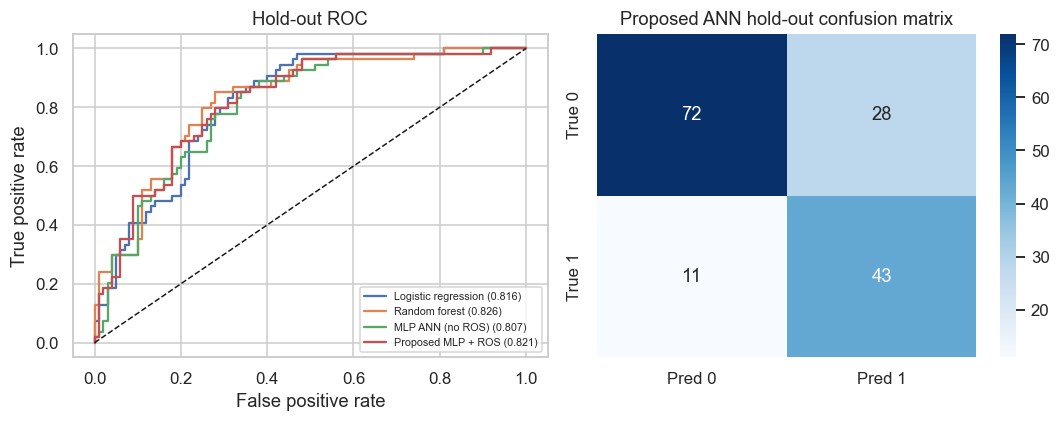

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for label, item in holdout.items():
    fpr, tpr, _ = roc_curve(y_te, item["proba"])
    axes[0].plot(fpr, tpr, label=f"{label} ({item['metrics']['roc_auc']:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1)
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].set_title("Hold-out ROC")
axes[0].legend(fontsize=7)

cm = confusion_matrix(y_te, holdout["Proposed MLP + ROS"]["pred"], labels=[0, 1])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[1],
            xticklabels=["Pred 0", "Pred 1"], yticklabels=["True 0", "True 1"])
axes[1].set_title("Proposed ANN hold-out confusion matrix")
plt.tight_layout()
plt.show()

## 11. Permutation importance

Shuffle one hold-out column at a time and measure the drop in ROC-AUC. Glucose should dominate.


/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_a

/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_a

/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_a

/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_a

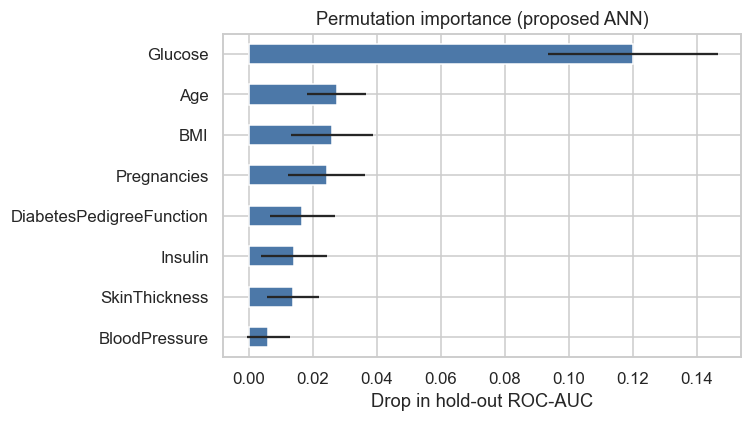

Glucose                     0.120
Age                         0.028
BMI                         0.026
Pregnancies                 0.024
DiabetesPedigreeFunction    0.017
Insulin                     0.014
SkinThickness               0.014
BloodPressure               0.006
dtype: float64


In [14]:
proposed = holdout["Proposed MLP + ROS"]["pipe"]
perm = permutation_importance(
    proposed, X_te, y_te, scoring="roc_auc", n_repeats=30, random_state=RANDOM_SEED
)
imp = pd.Series(perm.importances_mean, index=FEATURE_COLUMNS).sort_values()
err = pd.Series(perm.importances_std, index=FEATURE_COLUMNS).loc[imp.index]
imp.plot.barh(xerr=err, color="#4C78A8")
plt.xlabel("Drop in hold-out ROC-AUC")
plt.title("Permutation importance (proposed ANN)")
plt.tight_layout()
plt.show()
print(pd.Series(perm.importances_mean, index=FEATURE_COLUMNS).sort_values(ascending=False).round(3))

## 12. Prediction on new records

The saved pipeline recodes zeros, imputes, scales, and scores a probability. Oversampling is idle at prediction time. These two records are illustrations, not diagnoses.


In [15]:
demo = pd.DataFrame(
    [
        [6, 168, 72, 0, 0, 36.4, 0.627, 47],
        [1, 94, 66, 20, 80, 24.1, 0.249, 26],
    ],
    columns=FEATURE_COLUMNS,
    index=["High-risk illustration", "Low-risk illustration"],
)
proba = predict_proba_positive(proposed, demo)
pred = proposed.predict(demo)
out = demo.copy()
out["P(diabetes)"] = np.round(proba, 3)
out["Predicted class"] = pred
out

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,P(diabetes),Predicted class
High-risk illustration,6,168,72,0,0,36.4,0.627,47,0.937,1
Low-risk illustration,1,94,66,20,80,24.1,0.249,26,0.018,0


## 13. Small component check

These three variants keep the proposed ANN but drop one pipeline piece. They are scored on the same 5 folds so the gaps can be compared with the report ablation.


In [16]:
from sklearn.pipeline import Pipeline as SkPipeline

# No standardisation: keep the rest of the proposed recipe.
class NoScale:
    pass


def pipeline_no_scale(estimator):
    steps = [
        ("zero_as_missing", ZeroAsMissing(columns=ZERO_AS_MISSING_COLUMNS)),
        ("impute", SimpleImputer(strategy="median")),
        ("resample", RandomOverSampler(sampling_strategy="auto", random_state=RANDOM_SEED)),
        ("clf", clone(estimator)),
    ]
    return ImbPipeline(steps)


def pipeline_zeros_kept(estimator):
    steps = [
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("resample", RandomOverSampler(sampling_strategy="auto", random_state=RANDOM_SEED)),
        ("clf", clone(estimator)),
    ]
    return ImbPipeline(steps)


mlp = make_estimators()["MLP ANN 8-16-8-1"]
checks = {
    "Proposed (from CV)": results["Proposed MLP + ROS"]["summary"]["roc_auc"]["mean"],
    "No standardisation": cross_validate_model(pipeline_no_scale(mlp), X, y)["summary"]["roc_auc"]["mean"],
    "Zeros kept as real": cross_validate_model(pipeline_zeros_kept(mlp), X, y)["summary"]["roc_auc"]["mean"],
    "No ROS (from CV)": results["MLP ANN (no ROS)"]["summary"]["roc_auc"]["mean"],
}
for name, auc in checks.items():
    print(f"{name:24s}  ROC-AUC {auc:.3f}")

/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_a

/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_a

/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_a

/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_a

/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_a

/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_a

/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_a

/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_a

/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_a

Proposed (from CV)        ROC-AUC 0.834
No standardisation        ROC-AUC 0.720
Zeros kept as real        ROC-AUC 0.823
No ROS (from CV)          ROC-AUC 0.832


/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_ann/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:205: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/deepakvf/ANN/diabetes_a

## 14. Summary

| Item | Result in this notebook |
|------|-------------------------|
| Dataset | 768 rows, 8 predictors, 34.9% positive |
| Proposed model | MLP 8–16–8–1, 289 weights, Adam, L2, early stopping |
| Protocol | Stratified 5-fold CV + 80/20 hold-out; preprocess inside the training fold |
| Main finding | Ranking quality is close to logistic regression and the random forest. Training-fold oversampling raises sensitivity. Glucose is the strongest feature. |
| Not for diagnosis | Single historical cohort of adult Pima women; educational use only |

The full written report also includes 10×5 repeated CV, corrected t-tests, a larger ablation, leakage experiments, and nested CV. Those runs use the same pipeline that is defined in this notebook (`src/diabetes_prediction/` in the project folder).
